# 04 · LoRA fine-tuning

This notebook explains the fine-tuning setup and inspects the training run. The training itself lives in [`scripts/train_lora.py`](../scripts/train_lora.py), because a 1–2 hour GPU job is more robust as a script than as a notebook cell:

```bash
python scripts/train_lora.py               # full run
python scripts/train_lora.py --smoke-test  # 2-minute end-to-end check
```

## Design choices

**Classification head instead of text generation.** There are two common ways to fine-tune an LLM for classification:

1. keep the language-model head and train it to *generate* the word "positive", or
2. replace it with a small **classification head**: a linear layer from the last token's hidden state to 3 logits, trained with cross-entropy.

I use option 2 (`AutoModelForSequenceClassification`). It gives calibrated class probabilities, needs a single forward pass, cannot produce an invalid answer, and drops the 151k-word output layer from the loss computation. The zero-shot baseline in notebook 03 already measures what the generative interface can do without training.

**LoRA.** Full fine-tuning of 4B parameters needs optimiser states for every weight, roughly 4 × 4B × 4 bytes ≈ 64 GB, which is far beyond a 12 GB GPU. LoRA freezes the base weights $W$ and learns a low-rank update instead:

$$W' = W + \frac{\alpha}{r} BA, \qquad B \in \mathbb{R}^{d \times r},\ A \in \mathbb{R}^{r \times k},\ r \ll d$$

| setting | value | why |
|---|---|---|
| rank `r` | 16 | enough capacity for a 3-class task, still < 1% of parameters |
| `lora_alpha` | 32 | the usual α = 2r scaling |
| dropout | 0.05 | light regularisation on the adapter input |
| target modules | all attention **and** MLP projections | adapting the MLPs as well helps with a dialect the model has rarely seen |
| trainable head | `score` (2560 → 3) | new layer, trained fully |

**Memory budget on an RTX 5070 (12 GB, about 10.5 GB free with the desktop running):**
- frozen base weights in bf16: about 8.1 GB
- LoRA weights + AdamW states in fp32: 33M × 16 bytes ≈ 0.5 GB
- activations: kept small with **gradient checkpointing**, which recomputes each layer's activations in the backward pass instead of storing them

QLoRA (4-bit base weights) would free memory, but I didn't need it. bf16 LoRA fits, avoids quantisation error, and avoids `bitsandbytes`, which is still unreliable on Windows with Blackwell GPUs.

**Training settings:** 2 epochs, lr 1e-4 with cosine decay and 5% warm-up, batch 16, max 256 tokens, length-grouped batches (less padding). Every 600 steps the model is evaluated on the validation set, and the checkpoint with the best **validation macro-F1** is kept.

In [1]:
import sys
sys.path.insert(0, "../src")

import json

import matplotlib.pyplot as plt
import pandas as pd

from darija_sentiment.config import ADAPTER_DIR, BASE_MODEL
from darija_sentiment.metrics import save_figure

## How many parameters does LoRA actually train?

This only builds the model on the `meta` device, without allocating memory, to count parameters.

In [2]:
import torch
from peft import LoraConfig, TaskType, get_peft_model
from transformers import AutoConfig, AutoModelForSequenceClassification

from darija_sentiment.llm import LORA_TARGETS

config = AutoConfig.from_pretrained(BASE_MODEL, num_labels=3)
with torch.device("meta"):
    skeleton = AutoModelForSequenceClassification.from_config(config)
skeleton = get_peft_model(skeleton, LoraConfig(task_type=TaskType.SEQ_CLS, r=16, lora_alpha=32, target_modules=LORA_TARGETS))
skeleton.print_trainable_parameters()

per_module = {}
for name, p in skeleton.named_parameters():
    if p.requires_grad:
        # e.g. base_model.model.model.layers.0.self_attn.q_proj.lora_A.default.weight -> q_proj
        key = "score (head)" if "score" in name else name.split(".")[-4]
        per_module[key] = per_module.get(key, 0) + p.numel()
pd.Series(per_module, name="trainable params").sort_values(ascending=False).to_frame()

trainable params: 33,037,824 || all params: 4,055,513,600 || trainable%: 0.8146


,trainable params
up_proj,7077888
down_proj,7077888
gate_proj,7077888
q_proj,3833856
o_proj,3833856
k_proj,2064384
v_proj,2064384
score (head),7680


In [3]:
del skeleton

## The training run

In [4]:
log = json.loads((ADAPTER_DIR / "training_log.json").read_text(encoding="utf-8"))
print(f"training time:         {log['train_minutes']} min")
print(f"peak GPU memory:       {log['peak_gpu_memory_gb']} GB")
print(f"best val macro-F1:     {log['best_val_macro_f1']:.4f}")
print(f"best checkpoint:       {log['best_checkpoint']}")

history = pd.DataFrame(log["log_history"])
train_log = history.dropna(subset=["loss"])[["step", "epoch", "loss", "learning_rate"]]
eval_log = history.dropna(subset=["eval_macro_f1"])[["step", "epoch", "eval_loss", "eval_macro_f1", "eval_accuracy",
                                                     "eval_f1_negative", "eval_f1_neutral", "eval_f1_positive"]]
eval_log.round(4)

training time:         65.9 min
peak GPU memory:       10.59 GB
best val macro-F1:     0.8004
best checkpoint:       outputs\qwen3-4b-darija-sentiment-lora\checkpoints\checkpoint-3600


,step,epoch,eval_loss,eval_macro_f1,eval_accuracy,eval_f1_negative,eval_f1_neutral,eval_f1_positive
24,600,0.2402,0.6065,0.7367,0.7602,0.7735,0.5950,0.8415
49,1200,0.4804,0.5197,0.7751,0.8006,0.8148,0.6395,0.8711
74,1800,0.7206,0.5069,0.7787,0.8104,0.8229,0.6352,0.8779
99,2400,0.9608,0.4937,0.7848,0.8112,0.8170,0.6539,0.8836
124,3000,1.2010,0.4993,0.7889,0.8211,0.8389,0.6450,0.8827
149,3600,1.4412,0.5068,0.8004,0.8271,0.8421,0.6722,0.8870
174,4200,1.6813,0.5054,0.7938,0.8225,0.8379,0.6575,0.8858
199,4800,1.9215,0.5076,0.7982,0.8241,0.8398,0.6692,0.8856
207,4996,2.0000,0.5079,0.7981,0.8241,0.8401,0.6689,0.8853
209,4996,2.0000,0.5067,0.8005,0.8271,0.8422,0.6725,0.8868


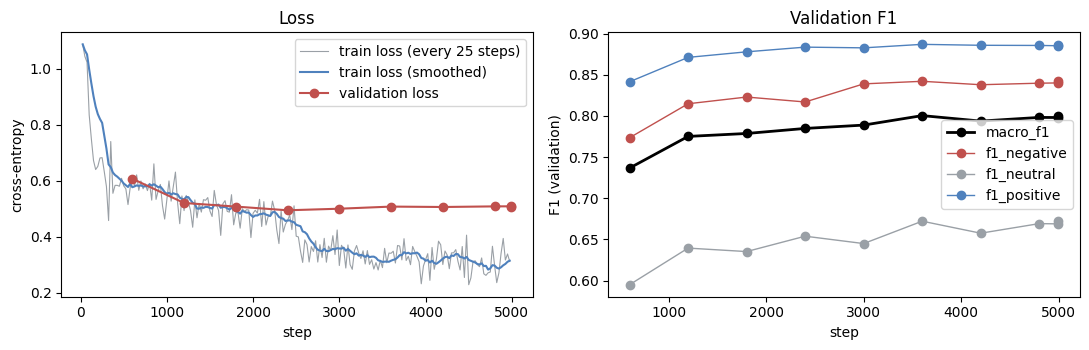

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(train_log["step"], train_log["loss"].astype(float), color="#9aa0a6", lw=0.8, label="train loss (every 25 steps)")
axes[0].plot(train_log["step"], train_log["loss"].astype(float).rolling(10, min_periods=1).mean(), color="#4f81bd", label="train loss (smoothed)")
axes[0].plot(eval_log["step"], eval_log["eval_loss"].astype(float), "o-", color="#c0504d", label="validation loss")
axes[0].set_xlabel("step"); axes[0].set_ylabel("cross-entropy"); axes[0].legend(); axes[0].set_title("Loss")

for col, color in [("eval_macro_f1", "k"), ("eval_f1_negative", "#c0504d"), ("eval_f1_neutral", "#9aa0a6"), ("eval_f1_positive", "#4f81bd")]:
    axes[1].plot(eval_log["step"], eval_log[col].astype(float), "o-", color=color, label=col.replace("eval_", ""), lw=2 if col == "eval_macro_f1" else 1)
axes[1].set_xlabel("step"); axes[1].set_ylabel("F1 (validation)"); axes[1].legend(); axes[1].set_title("Validation F1")
fig.tight_layout()
save_figure(fig, "training_curves")

Validation macro-F1 climbs quickly in the first half epoch (0.737 at step 600, 0.775 at step 1200). It then improves slowly to its peak of **0.800 at step 3600** (epoch 1.44) and levels off around 0.795–0.800 for the rest of training. A third epoch would probably not help.

Validation **loss** reaches its minimum at the end of epoch 1 (0.494) and then rises slightly, while **F1 keeps improving**. The model becomes more confident on the comments it gets right and more confidently wrong on the noisy ones, and cross-entropy penalises the latter heavily. The sharp drop in *training* loss around step 2,500 is the start of epoch 2: the model sees each comment for the second time, so training loss falls to about 0.3 while validation loss stays near 0.5. That is memorisation, not learning, and another reason more epochs wouldn't help. Choosing the checkpoint by macro-F1 rather than by loss gains about 1.5 points here (0.785 at the lowest-loss checkpoint vs 0.800).

The whole run took **66 minutes** with a peak of **10.6 GB** of GPU memory, which just fits next to the desktop on a 12 GB card.

## What gets saved

The adapter folder contains only what was trained: the LoRA matrices and the classification head. The base model is downloaded from the Hub when the adapter is loaded.

In [6]:
for f in sorted(ADAPTER_DIR.iterdir()):
    if f.is_file():
        print(f"{f.stat().st_size / 1e6:9.1f} MB  {f.name}")
print(json.dumps(json.loads((ADAPTER_DIR / "adapter_config.json").read_text()), indent=1)[:800])

      0.0 MB  adapter_config.json
    132.2 MB  adapter_model.safetensors
      0.0 MB  chat_template.jinja
      0.0 MB  README.md
     11.4 MB  tokenizer.json
      0.0 MB  tokenizer_config.json
      0.0 MB  training_log.json
{
 "alora_invocation_tokens": null,
 "alpha_pattern": {},
 "arrow_config": null,
 "auto_mapping": null,
 "base_model_name_or_path": "Qwen/Qwen3-4B-Instruct-2507",
 "bias": "none",
 "corda_config": null,
 "ensure_weight_tying": false,
 "eva_config": null,
 "exclude_modules": null,
 "fan_in_fan_out": false,
 "inference_mode": true,
 "init_lora_weights": true,
 "kasa_config": null,
 "layer_replication": null,
 "layers_pattern": null,
 "layers_to_transform": null,
 "loftq_config": {},
 "lora_alpha": 32,
 "lora_bias": false,
 "lora_dropout": 0.05,
 "lora_ga_config": null,
 "megatron_config": null,
 "megatron_core": "megatron.core",
 "modules_to_save": [
  "classifier",
  "score"
 ],
 "monteclora_config": null,
 "peft_type": "LORA",
 "peft_version": "0.21.2",
 "qalor